In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import subprocess
import sys
import matplotlib.pyplot as plt
import scipy.stats as stats
try:
    import statsmodels.api as sm  # noqa: F401
except ModuleNotFoundError:

    subprocess.check_call([sys.executable, "-m", "pip", "install", "statsmodels"])
    import statsmodels.api as sm  # noqa: F401

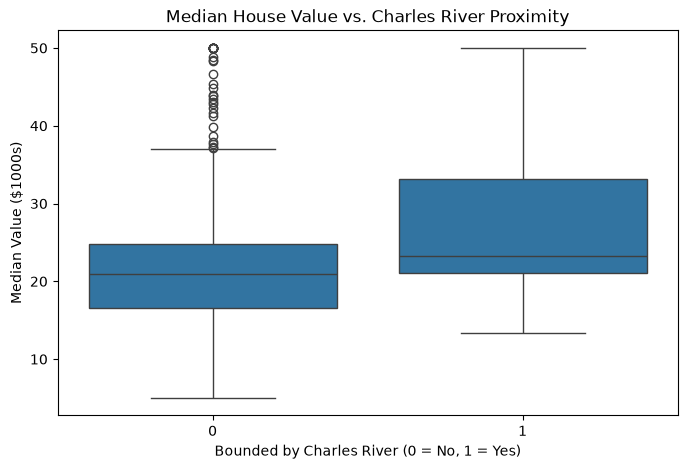

T-statistic: 3.996437466090509, P-value: 7.39062317051991e-05


In [6]:
# Visualization: Boxplot
plt.figure(figsize=(8, 5))

if 'df' not in globals():
    boston = sm.datasets.get_rdataset("Boston", "MASS")
    df = boston.data

sns.boxplot(x='chas', y='medv', data=df)
plt.title('Median House Value vs. Charles River Proximity')
plt.xlabel('Bounded by Charles River (0 = No, 1 = Yes)')
plt.ylabel('Median Value ($1000s)')
plt.show()

# Statistical Test
stat, p_value = stats.ttest_ind(
    df[df['chas'] == 1]['medv'],
    df[df['chas'] == 0]['medv'],
    equal_var=True
)
print(f"T-statistic: {stat}, P-value: {p_value}")

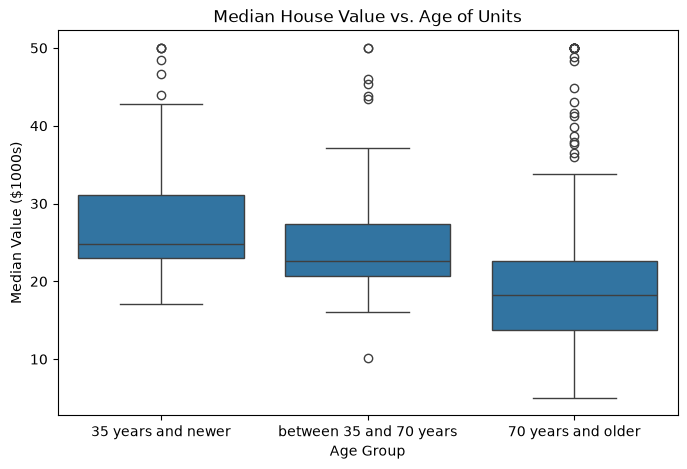

F-statistic: 36.40764999196598, P-value: 1.7105011022701524e-15


In [14]:
# Create age groups
df.loc[(df['age'] <= 35), 'age_group'] = '35 years and newer'
df.loc[(df['age'] > 35) & (df['age'] < 70), 'age_group'] = 'between 35 and 70 years'
df.loc[(df['age'] >= 70), 'age_group'] = '70 years and older'

# Visualization: Boxplot
plt.figure(figsize=(8, 5))
sns.boxplot(
    x='age_group',
    y='medv',
    data=df,
    order=['35 years and newer', 'between 35 and 70 years', '70 years and older']
)
plt.title('Median House Value vs. Age of Units')
plt.xlabel('Age Group')
plt.ylabel('Median Value ($1000s)')
plt.show()

# Statistical Test
thirtyfive_newer = df[df['age_group'] == '35 years and newer']['medv']
thirtyfive_seventy = df[df['age_group'] == 'between 35 and 70 years']['medv']
seventy_older = df[df['age_group'] == '70 years and older']['medv']
thirtyfive_seventy = df[df['age_group'] == 'between 35 and 70 years']['medv']
seventy_older = df[df['age_group'] == '70 years and older']['medv']

f_stat, p_value = stats.f_oneway(thirtyfive_newer, thirtyfive_seventy, seventy_older)
print(f"F-statistic: {f_stat}, P-value: {p_value}")

<Figure size 800x500 with 0 Axes>

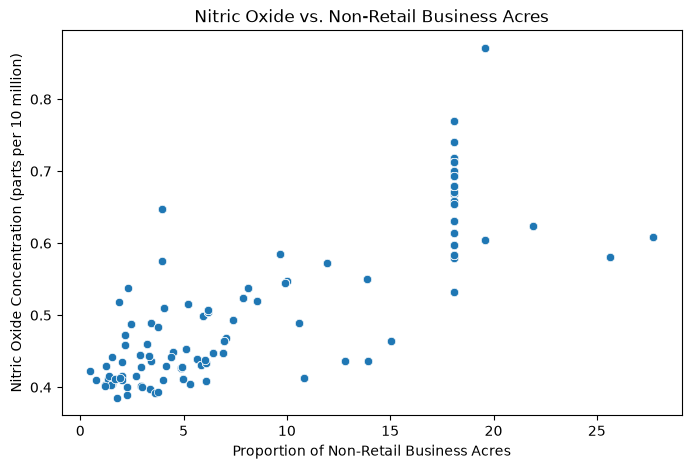

Pearson Correlation: 0.7636514469209154, P-value: 7.913361061239734e-98


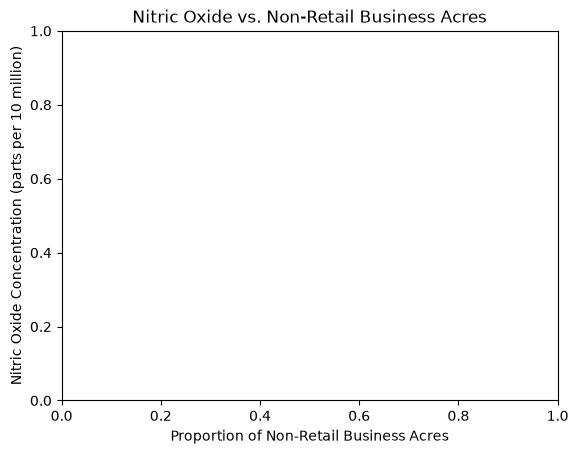

Pearson Correlation: 0.7636514469209154, P-value: 7.913361061239734e-98


In [17]:
# Visualization: Scatterplot
plt.figure(figsize=(8, 5))
# Visualization: Scatterplot
plt.figure(figsize=(8, 5))
sns.scatterplot(x='indus', y='nox', data=df)
plt.title('Nitric Oxide vs. Non-Retail Business Acres')
plt.xlabel('Proportion of Non-Retail Business Acres')
plt.ylabel('Nitric Oxide Concentration (parts per 10 million)')
plt.show()

# Statistical Test
corr, p_value = stats.pearsonr(df['indus'], df['nox'])
print(f"Pearson Correlation: {corr}, P-value: {p_value}")
plt.title('Nitric Oxide vs. Non-Retail Business Acres')
plt.xlabel('Proportion of Non-Retail Business Acres')
plt.ylabel('Nitric Oxide Concentration (parts per 10 million)')
plt.show()

# Statistical Test
corr, p_value = stats.pearsonr(df['indus'], df['nox'])
print(f"Pearson Correlation: {corr}, P-value: {p_value}")

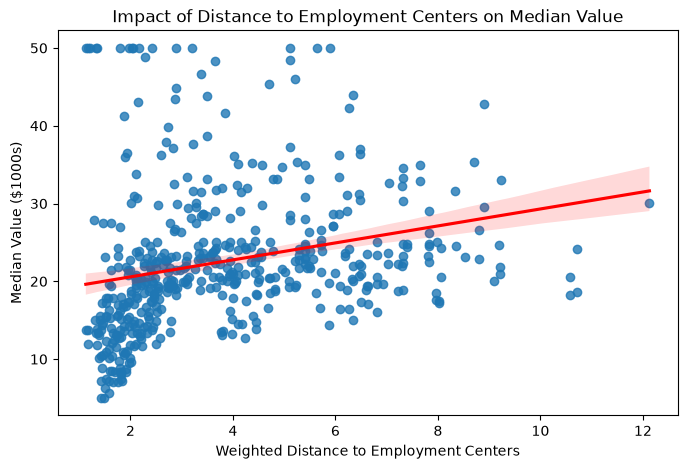

                            OLS Regression Results                            
Dep. Variable:                   medv   R-squared:                       0.062
Model:                            OLS   Adj. R-squared:                  0.061
Method:                 Least Squares   F-statistic:                     33.58
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           1.21e-08
Time:                        20:50:08   Log-Likelihood:                -1823.9
No. Observations:                 506   AIC:                             3652.
Df Residuals:                     504   BIC:                             3660.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         18.3901      0.817     22.499      0.0

In [23]:
# Visualization: Scatterplot with regression line
plt.figure(figsize=(8, 5))
sns.regplot(x='dis', y='medv', data=df, line_kws={"color": "red"})
plt.title('Impact of Distance to Employment Centers on Median Value')
plt.xlabel('Weighted Distance to Employment Centers')
plt.ylabel('Median Value ($1000s)')
plt.show()

# Statistical Test
X = df['dis']
y = df['medv']
X = sm.add_constant(X) # Add an intercept to the model

model = sm.OLS(y, X).fit()
print(model.summary())